# Search4Cure.AI: executable walkthrough

Run the cells in order. This notebook calls the project functions to query **real arXiv data**, download one version, extract text by physical PDF page, and create traceable text chunks. Running it again makes new source requests and creates new local retrieval/extraction records.

Use the **Search4Cure (.venv)** kernel after the notebook setup in the README. Saved outputs are snapshots of a particular execution, not evidence that the latest source results are unchanged.

Start Docker Desktop before running the database cells. They create a local password file, start PostgreSQL, and check the connection. No `.env` in `data/` is needed.

The document-storage cell imports real download metadata into PostgreSQL and shows the SQL row as a pandas DataFrame.

The raster-image cell saves PNG derivatives with page/position provenance and shows one reduced preview. It does not identify complete scientific figures.

The full-page cell renders every physical page and links its actual PNG to the text and chunk IDs from that same page. Embedded-image extraction remains a separate, available step.

The page-context storage cell imports page text, PNG references and processing states into PostgreSQL and checks a repeated import.

The text-chunk storage cell imports each exact text window into SQL, links it to matching page contexts, and verifies duplicate prevention and source offsets.

In [1]:
import json
import logging
import os
from pathlib import Path
import ssl
import subprocess
import sys
import time

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "arxiv_search.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "arxiv_search.py").is_file():
    raise RuntimeError("Open the notebook from the Search4Cure project directory.")
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

# Use an existing system trust store only when this macOS Python lacks a default CA file.
if sys.platform == "darwin" and ssl.get_default_verify_paths().cafile is None:
    system_ca = Path("/etc/ssl/cert.pem")
    if system_ca.is_file():
        os.environ["SSL_CERT_FILE"] = str(system_ca)
        print("Using the system CA bundle; HTTPS verification remains enabled.")

logging.basicConfig(level=logging.INFO, format="%(message)s", stream=sys.stdout, force=True)

import pymupdf
from arxiv_search import search_one
from download_pdf import download_pdf
from extract_text import extract_text
from chunk_text import chunk_text

QUERY = "all:diabetes"
# The working directory is the project root, including when opened from notebooks/.
OUTPUT_DIR = Path("data/arxiv")
print(f"Python {sys.version.split()[0]}; PyMuPDF {pymupdf.VersionBind}")
print(f"Search query: {QUERY}")
from database import HEALTH_SQL, PASSWORD_FILE, create_password_file, check_connection

from database import initialize_schema
from store_document import DOCUMENT_SQL, store_document, read_document

from extract_images import extract_images

from render_pages import render_pages

from store_pages import store_pages, read_page_contexts

from store_chunks import store_chunks, read_chunks, read_chunk_contexts


Using the system CA bundle; HTTPS verification remains enabled.
Python 3.13.12; PyMuPDF 1.28.2
Search query: all:diabetes


## 1. Query publication metadata

This cell contacts the arXiv API for at most one result. Keep first-submission time, version-submission time, and our retrieval time distinct. Unknown fields remain unknown.

In [2]:
print("Querying arXiv...")
search_result = search_one(QUERY)
if search_result["document"] is None:
    raise RuntimeError("No publication matched this query.")
print(json.dumps(search_result, indent=2, ensure_ascii=False))

Querying arXiv...


{
  "query": "all:diabetes",
  "request_url": "https://export.arxiv.org/api/query?search_query=all%3Adiabetes&start=0&max_results=1&sortBy=submittedDate&sortOrder=descending",
  "retrieved_at": "2026-11-05T14:33:21.021355+00:00",
  "document": {
    "arxiv_id": "2611.06569",
    "version": 1,
    "title": "One Scale, Four Texts: Gaps, Overlaps and Silent Repairs in Published Grading Schemes",
    "source_url": "http://arxiv.org/abs/2611.06569v1",
    "first_submitted_at": "2026-11-04T14:32:17Z",
    "version_submitted_at": "2026-11-04T14:32:17Z"
  }
}


## 2. Download the exact version

The download requires a known version, streams bytes to disk, and records a SHA-256 fingerprint and a separate PDF retrieval time. The pause respects the API request spacing. Only one importer should run at a time.

In [3]:
print("Waiting 3.1 seconds before the PDF request...")
time.sleep(3.1)
download_result = download_pdf(search_result, OUTPUT_DIR)
print(json.dumps(download_result, indent=2, ensure_ascii=False))

Waiting 3.1 seconds before the PDF request...


Downloaded 1048576 bytes


PDF saved: data/arxiv/2611.06569v1/2f790b9f3d12e90e39791bd304ee122de1dcd24ff12fdb992bd6a9759149a698.pdf (1324827 bytes)


Metadata saved: data/arxiv/2611.06569v1/d4d078a3eb424843ab6185a8fb0b0981.json


{
  "search": {
    "query": "all:diabetes",
    "request_url": "https://export.arxiv.org/api/query?search_query=all%3Adiabetes&start=0&max_results=1&sortBy=submittedDate&sortOrder=descending",
    "retrieved_at": "2026-11-05T14:33:21.021355+00:00",
    "document": {
      "arxiv_id": "2611.06569",
      "version": 1,
      "title": "One Scale, Four Texts: Gaps, Overlaps and Silent Repairs in Published Grading Schemes",
      "source_url": "http://arxiv.org/abs/2611.06569v1",
      "first_submitted_at": "2026-11-04T14:32:17Z",
      "version_submitted_at": "2026-11-04T14:32:17Z"
    }
  },
  "pdf_url": "https://arxiv.org/pdf/2611.06569v1",
  "pdf_retrieved_at": "2026-11-05T14:33:24.374436+00:00",
  "sha256": "2f790b9f3d12e90e39791bd304ee122de1dcd24ff12fdb992bd6a9759149a698",
  "size_bytes": 1324827,
  "local_path": "data/arxiv/2611.06569v1/2f790b9f3d12e90e39791bd304ee122de1dcd24ff12fdb992bd6a9759149a698.pdf",
  "status": "downloaded",
  "metadata_path": "data/arxiv/2611.06569v1/d4d078a

## 3. Extract text by physical PDF page

The extractor verifies the saved PDF hash before parsing it. It records the parser version/configuration, page numbers starting at 1, empty pages, and any NUL replacements. Each attempt creates its own JSON result; a failed attempt does not replace the source or a previous result.

In [4]:
extraction_result = extract_text(download_result["metadata_path"])
assert extraction_result["download"]["sha256"] == download_result["sha256"]
assert extraction_result["page_count"] == len(extraction_result["pages"])
summary = {
    "arxiv_id": extraction_result["download"]["search"]["document"]["arxiv_id"],
    "version": extraction_result["download"]["search"]["document"]["version"],
    "status": extraction_result["status"],
    "page_count": extraction_result["page_count"],
    "empty_pages": extraction_result["empty_pages"],
    "total_characters": extraction_result["total_characters"],
    "parser": extraction_result["parser"],
    "parser_repaired_pdf": extraction_result["parser_repaired_pdf"],
    "output": extraction_result["metadata_path"],
}
print(json.dumps(summary, indent=2, ensure_ascii=False))

Verifying PDF hash: data/arxiv/2611.06569v1/2f790b9f3d12e90e39791bd304ee122de1dcd24ff12fdb992bd6a9759149a698.pdf


Page 1/18: 4174 characters


Page 2/18: 4787 characters


Page 3/18: 4567 characters


Page 4/18: 4143 characters


Page 5/18: 2872 characters


... (11 outputs left out)

Page 17/18: 3886 characters


Page 18/18: 2491 characters


Extraction record saved: data/arxiv/2611.06569v1/extracted/7cd863584d65472ea2bf143c9eb72536.json


{
  "arxiv_id": "2611.06569",
  "version": 1,
  "status": "extracted",
  "page_count": 18,
  "empty_pages": [],
  "total_characters": 74456,
  "parser": {
    "name": "PyMuPDF",
    "version": "1.28.2",
    "text_mode": "text",
    "sort": true,
    "ocr": false,
    "page_numbering": "physical PDF pages, starting at 1",
    "nul_handling": "replace NUL with U+FFFD and record the replacement count"
  },
  "parser_repaired_pdf": false,
  "output": "data/arxiv/2611.06569v1/extracted/7cd863584d65472ea2bf143c9eb72536.json"
}


## 4. Split page text into traceable chunks

A word window keeps up to `MAX_WORDS` non-whitespace runs, with `OVERLAP_WORDS` repeated between adjacent windows. Chunks never cross page boundaries. Character offsets preserve the exact source slice. The chosen word count is a demonstration configuration, not a validated model-token budget or retrieval-quality optimum.

Chunk IDs include document version, PDF hash, parser/chunking configuration, page, and content. Equivalent reruns retain IDs even when retrieval records have new timestamps or filenames.

In [5]:
MAX_WORDS = 100
OVERLAP_WORDS = 20
chunk_result = chunk_text(extraction_result["metadata_path"],
                          max_words=MAX_WORDS, overlap_words=OVERLAP_WORDS)
print(json.dumps({
    "status": chunk_result["status"],
    "chunk_count": chunk_result["chunk_count"],
    "pages_without_text": chunk_result["pages_without_text"],
    "configuration": chunk_result["chunking"],
    "output": chunk_result["metadata_path"],
}, indent=2, ensure_ascii=False))

example = chunk_result["chunks"][0]
source_page = extraction_result["pages"][example["page_number"] - 1]
assert example["text"] == source_page["text"][example["start_char"]:example["end_char"]]
print("First chunk; its exact source-page slice was checked:")
print(json.dumps(example, indent=2, ensure_ascii=False))

Page 1/18: 8 chunks


Page 2/18: 9 chunks


Page 3/18: 8 chunks


Page 4/18: 9 chunks


Page 5/18: 5 chunks


Page 6/18: 6 chunks


... (10 outputs left out)

Page 17/18: 8 chunks


Page 18/18: 6 chunks


Chunk record saved: data/arxiv/2611.06569v1/chunks/97dfb8bb3eea46f795ffeec0afbfb59f.json


{
  "status": "chunked",
  "chunk_count": 140,
  "pages_without_text": [],
  "configuration": {
    "method": "page_word_windows_v1",
    "max_words": 100,
    "overlap_words": 20,
    "word_definition": "non-whitespace runs",
    "offsets": "Unicode character indices, end-exclusive",
    "cross_page": false
  },
  "output": "data/arxiv/2611.06569v1/chunks/97dfb8bb3eea46f795ffeec0afbfb59f.json"
}
First chunk; its exact source-page slice was checked:
{
  "chunk_id": "944e540ad4363a013e27f7675150615cd662263c21ba227e4ce99bcead575295",
  "arxiv_id": "2611.06569",
  "version": 1,
  "source_pdf_sha256": "2f790b9f3d12e90e39791bd304ee122de1dcd24ff12fdb992bd6a9759149a698",
  "page_number": 1,
  "chunk_number": 1,
  "start_char": 0,
  "end_char": 734,
  "text": "One Scale, Four Texts: Gaps, Overlaps and Silent Repairs in\nPublished Grading Schemes\n\nElisa Rovai1,†, Fabio Rovai2,*,†\n\n1University of Padua, Padua, Italy\n2The Tesseract Academy, London, United Kingdom\n\n\n         Abstract\n    

## 5. Inspect one page

Change `PAGE_NUMBER` and rerun only this cell to inspect a different page. These are physical PDF pages, which may differ from printed page labels. A nonempty extraction does not by itself prove correct reading order or scientific relevance.

In [6]:
PAGE_NUMBER = 1
page = extraction_result["pages"][PAGE_NUMBER - 1]
document = extraction_result["download"]["search"]["document"]
print(f"Source: {document['arxiv_id']}v{document['version']}, physical page {page['page_number']}")
print(f"Source URL: {document['source_url']}")
print(f"PDF SHA-256: {extraction_result['download']['sha256']}")
print(f"Page status: {page['status']}; NUL replacements: {page['nul_replacements']}")
print("\nText preview (first 500 characters):\n")
print(page["text"][:500])

Source: 2611.06569v1, physical page 1
Source URL: http://arxiv.org/abs/2611.06569v1
PDF SHA-256: 2f790b9f3d12e90e39791bd304ee122de1dcd24ff12fdb992bd6a9759149a698
Page status: extracted; NUL replacements: 0

Text preview (first 500 characters):

One Scale, Four Texts: Gaps, Overlaps and Silent Repairs in
Published Grading Schemes

Elisa Rovai1,†, Fabio Rovai2,*,†

1University of Padua, Padua, Italy
2The Tesseract Academy, London, United Kingdom


         Abstract
           Category systems often reach their users as text, and readers apply them with tacit repairs. We ask what such
           a text determines once the repairs are removed, using diabetic retinopathy grading, where one international
             scale circulates in seve


## 6. Prepare local PostgreSQL

The next cell creates `data/postgres/password.txt` only if it does not exist. It prints the path and status, never the password. The file is excluded from Git. No `.env` file is required.

Docker Compose starts a separate local PostgreSQL container and enables pgvector on first initialization. The first start may download the image. The database port is bound to `127.0.0.1` only. An existing password file is preserved; changing it does not update a password already stored in the database volume.

In [7]:
created = create_password_file()
print(f"Password file: {PASSWORD_FILE}")
print("Created; contents hidden." if created else "Already exists; kept unchanged; contents hidden.")
command = ["docker", "compose", "up", "-d", "--wait", "--wait-timeout", "60", "postgres"]
print("Running:", " ".join(command), flush=True)
with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                      text=True, bufsize=1) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
    exit_code = process.wait()
print(f"Docker process exit code: {exit_code}")
if exit_code != 0:
    raise RuntimeError("PostgreSQL startup failed. Check Docker Desktop and the output above.")

Password file: data/postgres/password.txt
Already exists; kept unchanged; contents hidden.
Running: docker compose up -d --wait --wait-timeout 60 postgres


 Container search4cure-local-postgres-1  Running


 Container search4cure-local-postgres-1  Waiting


 Container search4cure-local-postgres-1  Healthy


Docker process exit code: 0


## 7. Check the actual database

This read-only SQL query reports the connected database, PostgreSQL and pgvector versions, and the number of public tables. It does not import documents or create application tables. Connection and statement waits are limited to five seconds each. Credentials are not included in the result.

In [8]:
print("Read-only connection query:")
print(HEALTH_SQL.strip())
print(json.dumps(check_connection(), indent=2))

Read-only connection query:
SELECT current_database() AS database,
       current_user AS db_user,
       current_setting('server_version') AS postgres_version,
       (SELECT extversion FROM pg_extension WHERE extname = 'vector') AS pgvector_version,
       (SELECT count(*) FROM pg_tables WHERE schemaname = 'public') AS public_table_count,
       1 AS check_value;
Connecting to local PostgreSQL at 127.0.0.1:55432


{
  "database": "search4cure",
  "db_user": "search4cure",
  "postgres_version": "16.15 (Debian 16.15-1.pgdg12+2)",
  "pgvector_version": "0.8.7",
  "public_table_count": 2,
  "check_value": 1
}


## 8. Store one document version and display its SQL metadata

Initialize the SQL tables explicitly, then import the real download record from this run. Each `(arxiv_id, version)` can occur only once. The importer verifies the PDF fingerprint and size. Importing the same version and content again returns `unchanged`; a changed hash raises a conflict and preserves the stored row.

The SQL row keeps the first imported download snapshot. Later retrieval attempts remain in local JSON files. Source submission times are not exact public-availability times; unknown times stay `NULL`. The database storage time describes our own write.

A pandas DataFrame displays the SQL result in Python memory. This does not store page text, chunks or vectors in SQL. The download status does not assert successful parsing.

In [9]:
import pandas as pd

initialize_schema()
print("Document table initialized.")
started = time.perf_counter()
first_import = store_document(download_result["metadata_path"])
first_seconds = time.perf_counter() - started
started = time.perf_counter()
second_import = store_document(download_result["metadata_path"])
second_seconds = time.perf_counter() - started
print(f"Import durations (single local observation): {first_seconds:.6f}s; repeat {second_seconds:.6f}s")
print("First import in this run:", json.dumps(first_import))
print("Repeated import:", json.dumps(second_import))
assert second_import["status"] == "unchanged"
row = read_document(first_import["arxiv_id"], first_import["version"])
assert row["sha256"] == download_result["sha256"]
print("Parameterized SQL (values are passed separately):")
print(DOCUMENT_SQL.strip())
documents_df = pd.DataFrame([row])
print("Rows returned for this document version:", len(documents_df))
assert len(documents_df) == 1
print(documents_df[["arxiv_id", "version", "status", "size_bytes"]].to_string(index=False))
display(documents_df[["arxiv_id", "version", "title", "status", "pdf_retrieved_at", "stored_at"]])

Connecting to local PostgreSQL at 127.0.0.1:55432


Document table initialized.
Connecting to local PostgreSQL at 127.0.0.1:55432


Document metadata inserted: 2611.06569v1


Connecting to local PostgreSQL at 127.0.0.1:55432


Document metadata unchanged: 2611.06569v1


Import durations (single local observation): 0.025074s; repeat 0.015349s
First import in this run: {"status": "inserted", "arxiv_id": "2611.06569", "version": 1, "sha256": "2f790b9f3d12e90e39791bd304ee122de1dcd24ff12fdb992bd6a9759149a698"}
Repeated import: {"status": "unchanged", "arxiv_id": "2611.06569", "version": 1, "sha256": "2f790b9f3d12e90e39791bd304ee122de1dcd24ff12fdb992bd6a9759149a698"}
Connecting to local PostgreSQL at 127.0.0.1:55432


Parameterized SQL (values are passed separately):
SELECT arxiv_id, version, title, source_url, pdf_url, first_submitted_at,
       version_submitted_at, metadata_retrieved_at, pdf_retrieved_at,
       sha256, size_bytes, local_path, metadata_path, status, stored_at
FROM document_versions
WHERE arxiv_id = %s AND version = %s;
Rows returned for this document version: 1
  arxiv_id  version     status  size_bytes
2611.06569        1 downloaded     1324827


,arxiv_id,version,title,status,pdf_retrieved_at,stored_at
0,2611.06569,1,"One Scale, Four Texts: Gaps, Overlaps and Sile...",downloaded,2026-11-05 14:33:24.374436+00:00,2026-11-05 14:33:26.997683+00:00


## 9. Extract referenced raster images

This cell verifies the PDF hash, finds raster-image occurrences on each physical page, and saves PNG derivatives. A reused image has one content-addressed PNG and separate occurrence records for its pages and positions. Soft transparency masks are applied; non-gray/non-RGB color spaces are converted to RGB.

`extracted` means all reported raster occurrences were saved. `no_images` means none were reported; vector drawings and text can still be present. `partial` means at least one occurrence failed or lacks an extractable PDF object reference. Those failures remain in the attempt JSON. Inline/unresolved images have no fallback rendering.

Bounding boxes use unrotated PyMuPDF page coordinates in points. Rotation, clipping, overlays and captions are not reconstructed into complete figures. The source PDF remains unchanged. PNG files and attempt records stay local; image SQL storage and CLIP embeddings are later steps.

In [10]:
from IPython.display import Image, display

image_result = extract_images(download_result["metadata_path"])
print(json.dumps({key: image_result[key] for key in (
    "status", "page_count", "extracted_count", "unique_asset_count",
    "failed_count", "unsupported_count", "metadata_path",
)}, indent=2))
image_rows = [{key: item.get(key) for key in (
    "page_number", "image_number", "xref", "status", "width", "height", "error",
)} for item in image_result["images"]]
if image_rows:
    images_df = pd.DataFrame(image_rows)
    print(images_df.to_string(index=False))
    display(images_df)
else:
    print("No referenced raster images were reported; this is not evidence of a figure-free PDF.")

successful_images = [item for item in image_result["images"] if item["status"] == "extracted"]
if successful_images:
    example = successful_images[0]
    print(f"Preview source: {example['arxiv_id']}v{example['version']}, physical page {example['page_number']}, image {example['image_number']}")
    print("Source-page bounding box:", example["bbox"])
    print("Saved PNG:", example["local_path"])
    preview = pymupdf.Pixmap(example["local_path"])
    while max(preview.width, preview.height) > 800:
        preview.shrink(1)
    print(f"Reduced preview: {preview.width} x {preview.height}; stored image: {example['width']} x {example['height']}")
    display(Image(data=preview.tobytes("png")))
if image_result["status"] == "partial":
    print("PARTIAL extraction: inspect the failed/unsupported rows and the saved attempt JSON.")

Verifying PDF hash for image extraction: data/arxiv/2611.06569v1/2f790b9f3d12e90e39791bd304ee122de1dcd24ff12fdb992bd6a9759149a698.pdf


Page 1/18: 0 raster occurrences; 0 extracted


Page 2/18: 0 raster occurrences; 0 extracted


Page 3/18: 0 raster occurrences; 0 extracted


Page 4/18: 0 raster occurrences; 0 extracted


Page 5/18: 0 raster occurrences; 0 extracted


... (11 outputs left out)

Page 17/18: 0 raster occurrences; 0 extracted


Page 18/18: 0 raster occurrences; 0 extracted


Image extraction record saved: data/arxiv/2611.06569v1/images/d8c97857bd364a89bb910152ade90847.json


{
  "status": "no_images",
  "page_count": 18,
  "extracted_count": 0,
  "unique_asset_count": 0,
  "failed_count": 0,
  "unsupported_count": 0,
  "metadata_path": "data/arxiv/2611.06569v1/images/d8c97857bd364a89bb910152ade90847.json"
}
No referenced raster images were reported; this is not evidence of a figure-free PDF.


## 10. Preserve complete page context

Render every physical page, including pages without embedded raster images or extractable text. Each page has its own JSON record linking a full-page PNG, exact extracted page text, chunk IDs, document version and PDF hash. Input extraction/chunk snapshots must match this PDF and each other; chunk text must match the associated page slice.

The default is 144 DPI, RGB, white background, with annotations and PDF rotation respected. A full page means its complete visible PDF CropBox, as in a PDF viewer. Hidden content outside that box is not included. Rendering processes one page at a time and applies a configurable per-page pixel limit.

Page IDs identify the logical PDF page; render IDs additionally identify the rendering configuration. Successful PNGs are not rewritten on equivalent reruns. New JSON files represent new processing attempts. The renderer writes local records; the later page-context cell imports them into SQL. Search and model calls are not implemented yet.

This follows the text-plus-page-image design principle described in the [official OpenAI file-input documentation](https://developers.openai.com/api/docs/guides/file-inputs). The later answer step must load the selected pages' actual image bytes and associated text into a vision-capable model; a filename alone is not visual evidence.

Text extraction and image rendering have independent error handling. A text failure leaves `text=None` and records `text_error`, while `image_status="rendered"` identifies a usable PNG. The attempt is `partial` and the CLI returns a nonzero status until the text failure is resolved. An empty text string remains a successful, empty extraction.

Verifying PDF hash for full-page rendering: data/arxiv/2611.06569v1/2f790b9f3d12e90e39791bd304ee122de1dcd24ff12fdb992bd6a9759149a698.pdf


Full page 1/18: rendered; text=extracted; linked chunks=8


Full page 2/18: rendered; text=extracted; linked chunks=9


Full page 3/18: rendered; text=extracted; linked chunks=8


Full page 4/18: rendered; text=extracted; linked chunks=9


Full page 5/18: rendered; text=extracted; linked chunks=5


... (13 outputs left out)

Full-page attempt record saved: data/arxiv/2611.06569v1/pages/53727ad2f4334cdca555f270a00b1f8c.json


{
  "status": "rendered",
  "page_count": 18,
  "rendered_count": 18,
  "failed_count": 0,
  "text_failed_count": 0,
  "image_failed_count": 0,
  "metadata_path": "data/arxiv/2611.06569v1/pages/53727ad2f4334cdca555f270a00b1f8c.json"
}
 page   status text_status image_status  width  height  text_characters  linked_chunks error
    1 rendered   extracted     rendered   1191    1684             4174              8  None
    2 rendered   extracted     rendered   1191    1684             4787              9  None
    3 rendered   extracted     rendered   1191    1684             4567              8  None
    4 rendered   extracted     rendered   1191    1684             4143              9  None
    5 rendered   extracted     rendered   1191    1684             2872              5  None
    6 rendered   extracted     rendered   1191    1684             3366              6  None
    7 rendered   extracted     rendered   1191    1684             5119              8  None
    8 rendered   extr

,page,status,text_status,image_status,width,height,text_characters,linked_chunks,error
0,1,rendered,extracted,rendered,1191,1684,4174,8,None
1,2,rendered,extracted,rendered,1191,1684,4787,9,None
2,3,rendered,extracted,rendered,1191,1684,4567,8,None
3,4,rendered,extracted,rendered,1191,1684,4143,9,None
4,5,rendered,extracted,rendered,1191,1684,2872,5,None
5,6,rendered,extracted,rendered,1191,1684,3366,6,None
6,7,rendered,extracted,rendered,1191,1684,5119,8,None
7,8,rendered,extracted,rendered,1191,1684,4793,9,None
8,9,rendered,extracted,rendered,1191,1684,4544,9,None
9,10,rendered,extracted,rendered,1191,1684,4397,9,None


Source: 2611.06569v1, physical PDF page 3
Page record: data/arxiv/2611.06569v1/pages/records/c4a7a59deebd4225b4e9baf7fea9a806.json
PDF SHA-256: 2f790b9f3d12e90e39791bd304ee122de1dcd24ff12fdb992bd6a9759149a698
Associated page text (first 400 characters):
Table 1
Clinical terms used in the paper. The definitions are those a reader needs to follow the rules; none of our claims
depends on clinical knowledge beyond them.

term                      meaning

DR; NPDR, PDR                diabetic retinopathy, damage to the retinal vessels caused by diabetes; its non-proliferative
                         and proliferative stages. Proliferative disease is
Actual full-page PNG: data/arxiv/2611.06569v1/pages/assets/741ac0578a9a4ae8b08c66d565af9bf0a42ca901fd7b07e839cedd57824dd1e0.png
Reduced notebook preview: 596 x 842


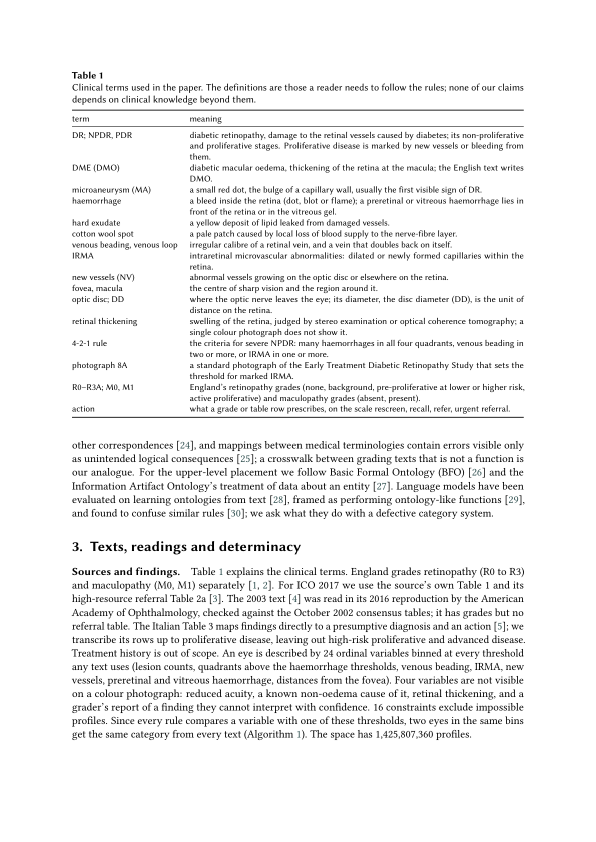

In [11]:
import hashlib

page_result = render_pages(
    download_result["metadata_path"],
    extraction_path=extraction_result["metadata_path"],
    chunks_path=chunk_result["metadata_path"],
    dpi=144,
)
print(json.dumps({key: page_result[key] for key in (
    "status", "page_count", "rendered_count", "failed_count",
    "text_failed_count", "image_failed_count", "metadata_path",
)}, indent=2))
page_rows = [{
    "page": item["page_number"], "status": item["status"],
    "text_status": item["text_status"], "image_status": item["image_status"],
    "width": item["image"]["width"] if item["image"] else None,
    "height": item["image"]["height"] if item["image"] else None,
    "text_characters": len(item["text"]) if item["text"] is not None else None,
    "linked_chunks": len(item["chunk_ids"]), "error": item["error"],
} for item in page_result["pages"]]
pages_df = pd.DataFrame(page_rows)
print(pages_df.to_string(index=False))
display(pages_df)

PAGE_TO_SHOW = min(3, page_result["page_count"])
selected_page = next(item for item in page_result["pages"] if item["page_number"] == PAGE_TO_SHOW)
assert selected_page["text"] == extraction_result["pages"][PAGE_TO_SHOW - 1]["text"]
assert selected_page["chunk_ids"] == [c["chunk_id"] for c in chunk_result["chunks"] if c["page_number"] == PAGE_TO_SHOW]
print(f"Source: {selected_page['arxiv_id']}v{selected_page['version']}, physical PDF page {PAGE_TO_SHOW}")
print("Page record:", selected_page.get("record_path"))
print("PDF SHA-256:", selected_page["source_pdf_sha256"])
print("Associated page text (first 400 characters):")
print(selected_page["text"][:400])
if selected_page["image"] is not None:
    png_path = Path(selected_page["image"]["local_path"])
    assert hashlib.sha256(png_path.read_bytes()).hexdigest() == selected_page["image"]["sha256"]
    print("Actual full-page PNG:", png_path)
    preview = pymupdf.Pixmap(str(png_path))
    while max(preview.width, preview.height) > 1000:
        preview.shrink(1)
    print(f"Reduced notebook preview: {preview.width} x {preview.height}")
    display(Image(data=preview.tobytes("png")))
if page_result["status"] != "rendered":
    print("INCOMPLETE page rendering: inspect failed page records before using them as evidence.")

## 10a. Synthetic example: keep the image after a text error

This offline example generates a small temporary PDF and deliberately makes `get_text()` raise an exception. It is a simulated failure, not an observed problem with the arXiv publication. No synthetic record is imported into SQL. The example verifies that the actual PNG exists, the failed text remains unknown, and a retry recovers text without rewriting the existing PNG.

In [12]:
import tempfile
from unittest.mock import patch

with tempfile.TemporaryDirectory(prefix="search4cure-synthetic-") as directory:
    demo_root = Path(directory)
    demo_pdf = demo_root / "SYNTHETIC.pdf"
    with pymupdf.open() as pdf:
        page = pdf.new_page(width=160, height=200)
        page.insert_text((15, 30), "SYNTHETIC text-error demo", fontsize=8)
        pdf.save(demo_pdf)
    demo_metadata = demo_root / "SYNTHETIC-download.json"
    demo_metadata.write_text(json.dumps({
        "status": "downloaded", "local_path": str(demo_pdf),
        "sha256": hashlib.sha256(demo_pdf.read_bytes()).hexdigest(),
        "search": {"query": "SYNTHETIC TEST ONLY", "document": {
            "arxiv_id": "2401.00001", "version": 1, "title": "SYNTHETIC fixture",
        }},
    }))
    with patch("render_pages.pymupdf.Page.get_text",
               side_effect=RuntimeError("SYNTHETIC text extraction failure")):
        demo_failed = render_pages(demo_metadata, dpi=72)
    demo_page = demo_failed["pages"][0]
    demo_png = Path(demo_page["image"]["local_path"])
    assert demo_page["text"] is None
    assert demo_page["text_status"] == "failed"
    assert demo_page["image_status"] == "rendered" and demo_png.is_file()
    print("SYNTHETIC failure result:")
    print(json.dumps({
        "attempt_status": demo_failed["status"], "text": demo_page["text"],
        "text_error": demo_page["text_error"], "image_status": demo_page["image_status"],
        "PNG_exists": demo_png.is_file(),
    }, indent=2))
    saved_mtime = demo_png.stat().st_mtime_ns
    demo_retry = render_pages(demo_metadata, dpi=72)
    assert demo_retry["status"] == "rendered"
    assert demo_retry["pages"][0]["text_status"] == "extracted"
    assert demo_png.stat().st_mtime_ns == saved_mtime
    print("Retry: text recovered; existing PNG kept unchanged.")

Verifying PDF hash for full-page rendering: /var/folders/69/7fyqgvhj7yqctsqk4wr745jc0000gn/T/search4cure-synthetic-7ajt4097/SYNTHETIC.pdf


Page 1 text extraction failed: RuntimeError: SYNTHETIC text extraction failure


Full page 1/1: rendered; text=failed; linked chunks=0


Full-page attempt record saved: /var/folders/69/7fyqgvhj7yqctsqk4wr745jc0000gn/T/search4cure-synthetic-7ajt4097/pages/c627e4602f454fffb7165c455fc28e17.json


SYNTHETIC failure result:
{
  "attempt_status": "partial",
  "text": null,
  "text_error": "RuntimeError: SYNTHETIC text extraction failure",
  "image_status": "rendered",
  "PNG_exists": true
}
Verifying PDF hash for full-page rendering: /var/folders/69/7fyqgvhj7yqctsqk4wr745jc0000gn/T/search4cure-synthetic-7ajt4097/SYNTHETIC.pdf


Full page 1/1: rendered; text=extracted; linked chunks=0


Full-page attempt record saved: /var/folders/69/7fyqgvhj7yqctsqk4wr745jc0000gn/T/search4cure-synthetic-7ajt4097/pages/e505af751064403b87a451ec5e4b7be2.json


Retry: text recovered; existing PNG kept unchanged.


## 11. Store page contexts in PostgreSQL

Each page is linked by document version and exact PDF hash to its parent in `document_versions`. The importer validates text/PNG fingerprints, identities and image dimensions. PNG bytes remain on disk; SQL stores their references and the page text.

A semantic context ID includes page/render identity, content, parser configuration, chunk IDs, statuses and errors. Attempt paths and times are excluded, so equivalent reruns do not create new rows. A recovered or differently configured context is a new snapshot; previous failures remain visible. The first snapshot's paths/times are retained.

Each page has its own transaction. The importer can return a partial result without losing other pages. The processing status stored in a context is distinct from the SQL import status. This cell imports only real source data; synthetic SQL tests use rolled-back isolated schemas.

The SQL importer also reopens the referenced extraction/chunk snapshots and validates each chunk ID against its original page assignment. A syntactically valid ID from the wrong page is rejected.

In [13]:
initialize_schema()
document = download_result["search"]["document"]
identifier, version = document["arxiv_id"], document["version"]
before_count = len(read_page_contexts(identifier, version))
started = time.perf_counter()
page_import = store_pages(page_result["metadata_path"])
first_seconds = time.perf_counter() - started
after_first = read_page_contexts(identifier, version)
started = time.perf_counter()
page_repeat = store_pages(page_result["metadata_path"])
repeat_seconds = time.perf_counter() - started
sql_pages = read_page_contexts(identifier, version)
assert page_import["failed_count"] == page_repeat["failed_count"] == 0
assert page_repeat["inserted_count"] == 0
assert len(sql_pages) == len(after_first)
print("Context rows before import:", before_count)
measurements_df = pd.DataFrame([
    {"operation": "first import", "inserted": page_import["inserted_count"],
     "unchanged": page_import["unchanged_count"], "rows_after": len(after_first), "seconds": first_seconds},
    {"operation": "repeat", "inserted": page_repeat["inserted_count"],
     "unchanged": page_repeat["unchanged_count"], "rows_after": len(sql_pages), "seconds": repeat_seconds},
])
print(measurements_df.to_string(index=False))
display(measurements_df)

fresh_ids = {item["context_id"] for item in page_import["pages"]}
current_contexts = [row for row in sql_pages if row["context_id"] in fresh_ids]
assert len(current_contexts) == page_result["page_count"]
for row in current_contexts:
    original = page_result["pages"][row["page_number"] - 1]
    assert row["page_text"] == original["text"]
    assert row["png_sha256"] == original["image"]["sha256"]
    assert row["chunk_ids"] == original["chunk_ids"]
contexts_df = pd.DataFrame(current_contexts)
print(contexts_df[["page_number", "text_status", "image_status", "status"]].to_string(index=False))
display(contexts_df[["page_number", "context_id", "text_status", "image_status", "png_path"]])

sql_example = next(row for row in current_contexts if row["page_number"] == PAGE_TO_SHOW)
assert hashlib.sha256(Path(sql_example["png_path"]).read_bytes()).hexdigest() == sql_example["png_sha256"]
print(f"SQL source: {sql_example['arxiv_id']}v{sql_example['version']}, physical page {sql_example['page_number']}")
print("Associated SQL text (first 200 characters):")
print(sql_example["page_text"][:200])
print("Referenced PNG exists and matches its SQL fingerprint.")
print("Timings are single local observations, not a speed benchmark.")

Connecting to local PostgreSQL at 127.0.0.1:55432


Connecting to local PostgreSQL at 127.0.0.1:55432


Connecting to local PostgreSQL at 127.0.0.1:55432


Page SQL import: inserted=18 unchanged=0 failed=0


Connecting to local PostgreSQL at 127.0.0.1:55432


Connecting to local PostgreSQL at 127.0.0.1:55432


... (3 outputs left out)

,operation,inserted,unchanged,rows_after,seconds
0,first import,18,0,18,0.386745
1,repeat,0,18,18,0.313573


 page_number text_status image_status   status
           1   extracted     rendered rendered
           2   extracted     rendered rendered
           3   extracted     rendered rendered
           4   extracted     rendered rendered
           5   extracted     rendered rendered
           6   extracted     rendered rendered
           7   extracted     rendered rendered
           8   extracted     rendered rendered
           9   extracted     rendered rendered
          10   extracted     rendered rendered
          11   extracted     rendered rendered
          12   extracted     rendered rendered
          13   extracted     rendered rendered
          14   extracted     rendered rendered
          15   extracted     rendered rendered
          16   extracted     rendered rendered
          17   extracted     rendered rendered
          18   extracted     rendered rendered


,page_number,context_id,text_status,image_status,png_path
0,1,061b7b733292127434e80f070a509c91c66c7b36d388aa...,extracted,rendered,data/arxiv/2611.06569v1/pages/assets/5f3de3c1d...
1,2,5dd37603aa2ebb5d624fbaf3c00282ddaf89d2a19b4154...,extracted,rendered,data/arxiv/2611.06569v1/pages/assets/8008a7f6f...
2,3,f419e0497437f398a5d4616f3901872fb81cf800b093a2...,extracted,rendered,data/arxiv/2611.06569v1/pages/assets/741ac0578...
3,4,b9f95a1da250ad8922ef97eba9bf474b83a731def58949...,extracted,rendered,data/arxiv/2611.06569v1/pages/assets/b89fe6818...
4,5,14fd1f283493b98e551a5cd5f60f7cda52d977a81f0fb3...,extracted,rendered,data/arxiv/2611.06569v1/pages/assets/34ccc584b...
5,6,f9189ab87cee68b3a95ee90a6950d4ddd490d0b14b5de0...,extracted,rendered,data/arxiv/2611.06569v1/pages/assets/80c447ff1...
6,7,be0005db098576b52fb00d5f5123692d9495fec884629d...,extracted,rendered,data/arxiv/2611.06569v1/pages/assets/dc08b4f53...
7,8,f34251e2c5c5c2c3bddd9cabca3ad52c3a65704f1ceba2...,extracted,rendered,data/arxiv/2611.06569v1/pages/assets/dff653796...
8,9,2fa5b4c58954780de0df128cf97b78fd6c8541405c6cca...,extracted,rendered,data/arxiv/2611.06569v1/pages/assets/e3220f838...
9,10,90ac35220ad84439614594448478643237618c8ddebb59...,extracted,rendered,data/arxiv/2611.06569v1/pages/assets/0257a21c0...


SQL source: 2611.06569v1, physical page 3
Associated SQL text (first 200 characters):
Table 1
Clinical terms used in the paper. The definitions are those a reader needs to follow the rules; none of our claims
depends on clinical knowledge beyond them.

term                      meaning
Referenced PNG exists and matches its SQL fingerprint.
Timings are single local observations, not a speed benchmark.


## 12. Store text chunks and follow their page links

The parent document and matching page contexts must already be imported by cells 8 and 11. The importer checks the original PDF/extraction and regenerates all recorded word windows and IDs before SQL writes. Each chunk is stored once; a separate link table connects it to matching page contexts. Another PNG resolution can add links without copying chunk text.

This cell imports real chunks twice, reports row/link counts and single-run durations, and checks an exact SQL text slice against its associated page. Different chunking policies remain separate variants. Reads do not rank relevance or choose a policy. A valid text context can have a failed image; vision use requires a usable image and its actual bytes. No embeddings or model requests occur here.


In [14]:
before_chunks = read_chunks(identifier, version)
started = time.perf_counter()
chunk_import = store_chunks(chunk_result["metadata_path"])
chunk_first_seconds = time.perf_counter() - started
after_first_chunks = read_chunks(identifier, version)
started = time.perf_counter()
chunk_repeat = store_chunks(chunk_result["metadata_path"])
chunk_repeat_seconds = time.perf_counter() - started
sql_chunks = read_chunks(identifier, version)
assert chunk_import["failed_count"] == chunk_repeat["failed_count"] == 0
assert chunk_repeat["inserted_count"] == chunk_repeat["linked_count"] == 0
assert len(sql_chunks) == len(after_first_chunks)
print("Chunk rows before import:", len(before_chunks))
print("Context links before import:", sum(row["context_count"] for row in before_chunks))
chunk_measurements = pd.DataFrame([
    {"operation": "first import", "inserted": chunk_import["inserted_count"],
     "unchanged": chunk_import["unchanged_count"], "new_links": chunk_import["linked_count"],
     "rows_after": len(after_first_chunks), "links_after": sum(row["context_count"] for row in after_first_chunks),
     "seconds": chunk_first_seconds},
    {"operation": "repeat", "inserted": chunk_repeat["inserted_count"],
     "unchanged": chunk_repeat["unchanged_count"], "new_links": chunk_repeat["linked_count"],
     "rows_after": len(sql_chunks), "links_after": sum(row["context_count"] for row in sql_chunks),
     "seconds": chunk_repeat_seconds},
])
print(chunk_measurements.to_string(index=False))
display(chunk_measurements)
current_ids = {chunk["chunk_id"] for chunk in chunk_result["chunks"]}
current_chunks = [row for row in sql_chunks if row["chunk_id"] in current_ids]
assert len(current_chunks) == chunk_result["chunk_count"]
original_chunks = {chunk["chunk_id"]: chunk for chunk in chunk_result["chunks"]}
for row in current_chunks:
    assert row["chunk_text"] == original_chunks[row["chunk_id"]]["text"]
    page_text = extraction_result["pages"][row["page_number"] - 1]["text"]
    assert row["chunk_text"] == page_text[row["start_char"]:row["end_char"]]
chunks_df = pd.DataFrame(current_chunks)
display(chunks_df[["page_number", "chunk_number", "word_count", "start_char", "end_char", "context_count"]])
example_chunk = current_chunks[0]
linked_contexts = read_chunk_contexts(example_chunk["chunk_id"])
assert linked_contexts
for context in linked_contexts:
    assert context["page_number"] == example_chunk["page_number"]
    assert context["source_pdf_sha256"] == example_chunk["source_pdf_sha256"]
    assert context["page_text"][context["start_char"]:context["end_char"]] == context["chunk_text"]
usable_context = next(row for row in linked_contexts if row["image_status"] == "rendered")
assert hashlib.sha256(Path(usable_context["png_path"]).read_bytes()).hexdigest() == usable_context["png_sha256"]
print(f"Verified {len(current_chunks)} SQL chunk texts against this run's extracted pages.")
print(f"Example source: {usable_context['arxiv_id']}v{usable_context['version']}, physical page {usable_context['page_number']}")
print(example_chunk["chunk_text"])
print("Associated PNG exists and matches its stored fingerprint.")
print("No embeddings or model calls were made. Timings are single local observations.")


Connecting to local PostgreSQL at 127.0.0.1:55432


Connecting to local PostgreSQL at 127.0.0.1:55432


Chunk SQL import: inserted=140 unchanged=0 new_links=140 failed=0


Connecting to local PostgreSQL at 127.0.0.1:55432


Connecting to local PostgreSQL at 127.0.0.1:55432


Chunk SQL import: inserted=0 unchanged=140 new_links=0 failed=0


... (2 outputs left out)

,operation,inserted,unchanged,new_links,rows_after,links_after,seconds
0,first import,140,0,140,140,140,0.409506
1,repeat,0,140,0,140,140,0.436360


,page_number,chunk_number,word_count,start_char,end_char,context_count
0,1,1,100,0,734,1
1,1,2,100,614,1269,1
2,1,3,100,1153,1797,1
3,1,4,100,1660,2458,1
4,1,5,100,2243,2914,1
...,...,...,...,...,...,...
135,18,2,100,468,1095,1
136,18,3,100,973,1571,1
137,18,4,100,1450,2064,1
138,18,5,100,1950,2483,1


Connecting to local PostgreSQL at 127.0.0.1:55432


Verified 140 SQL chunk texts against this run's extracted pages.
Example source: 2611.06569v1, physical page 1
One Scale, Four Texts: Gaps, Overlaps and Silent Repairs in
Published Grading Schemes

Elisa Rovai1,†, Fabio Rovai2,*,†

1University of Padua, Padua, Italy
2The Tesseract Academy, London, United Kingdom


         Abstract
           Category systems often reach their users as text, and readers apply them with tacit repairs. We ask what such
           a text determines once the repairs are removed, using diabetic retinopathy grading, where one international
             scale circulates in several documents. We transcribe four texts (the English screening definitions of 2025, the
            international scale as tabulated in 2017 and as published in 2003, and an Italian guideline of 2015) into one rule
           language
Associated PNG exists and matches its stored fingerprint.
No embeddings or model calls were made. Timings are single local observations.


## 13. Run the tests

API and PDF tests use synthetic responses and generated files. Opt-in integration tests contact the actual PostgreSQL database. Document tests use explicitly synthetic download records in isolated schemas that are rolled back after each test; they do not add synthetic documents to the application table. Expected synthetic network-failure warnings exercise error handling. The final unittest result determines success.

In [15]:
command = [
    sys.executable, "-u", "-m", "unittest", "discover",
    "-s", "tests", "-p", "test_*.py", "-v",
]
print("Running offline tests and actual PostgreSQL integration tests...", flush=True)
with subprocess.Popen(command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                      text=True, bufsize=1, env={**os.environ, "S4C_TEST_POSTGRES": "1"}) as process:
    for line in process.stdout:
        print(line, end="", flush=True)
    exit_code = process.wait()
print(f"Test process exit code: {exit_code}")
if exit_code != 0:
    raise RuntimeError("The tests failed.")

Running offline tests and actual PostgreSQL integration tests...


test_empty_and_invalid_entries (test_arxiv_search.ArxivSearchTests.test_empty_and_invalid_entries) ... ok


test_rate_limit_and_retry_after_stop_automatic_retries (test_arxiv_search.ArxivSearchTests.test_rate_limit_and_retry_after_stop_automatic_retries) ... WARNING:root:arXiv request failed: attempt=1/3 error=HTTP Error 429: Synthetic HTTP error


ok


test_real_request_shape_limits_results_and_sets_timeout (test_arxiv_search.ArxivSearchTests.test_real_request_shape_limits_results_and_sets_timeout) ... ok


test_retries_stop_after_three_attempts (test_arxiv_search.ArxivSearchTests.test_retries_stop_after_three_attempts) ... WARNING:root:arXiv request failed: attempt=1/3 error=<urlopen error Synthetic connection failure>


... (137 outputs left out)

----------------------------------------------------------------------


Ran 118 tests in 3.323s


OK


Test process exit code: 0


## 14. Inspect the original embedding models without running them

This independent inspection reads the pinned legacy Git source and the saved **real official configuration metadata** in `docs/model_review.json`. It needs neither model libraries nor a database/network connection. Dimensions and limits are configuration findings; no model inference or token counting occurs.

The routing probe executes only the legacy `vector_search()` function with **synthetic encoder stand-ins and an empty fake collection**. It shows which field is selected, not search quality. It reproduces the text-to-image routing mismatch and the optional Voyage-mode encoder mismatch; it does not fix either legacy function.

This section can be run independently. Its saved output is from a separate review execution; earlier pipeline/test outputs retain their own execution history. See [the model review](../docs/MODEL_REVIEW.md) for sources and unverified assumptions.


In [1]:
import ast
from importlib.metadata import PackageNotFoundError, version as package_version
import json
from pathlib import Path
import subprocess
from typing import Any, Dict, List, Union

review_root = Path.cwd()
if not (review_root / "docs/model_review.json").is_file():
    review_root = review_root.parent
review = json.loads((review_root / "docs/model_review.json").read_text())
legacy_commit = review["legacy_commit"]

def reviewed_source(path):
    return subprocess.check_output(
        ["git", "show", f"{legacy_commit}:{path}"], cwd=review_root, text=True,
    )

models = {item["model_id"]: item for item in review["models"]}
for filename in ("sbert.py", "clip.py"):
    tree = ast.parse(reviewed_source(f"backend/embeddings/{filename}"))
    names = [ast.literal_eval(node.args[0]) for node in ast.walk(tree)
             if isinstance(node, ast.Call) and isinstance(node.func, ast.Name)
             and node.func.id == "SentenceTransformer"]
    assert len(names) == 1
    assert "sentence-transformers/" + names[0] in models
    print(f"Legacy {filename}: {names[0]}")
mini = models["sentence-transformers/all-MiniLM-L6-v2"]["files"]
clip = models["sentence-transformers/clip-ViT-B-32"]["files"]
mini_dimension = mini["1_Pooling/config.json"]["configuration"]["word_embedding_dimension"]
mini_limit = mini["sentence_bert_config.json"]["configuration"]["max_seq_length"]
clip_config = clip["0_CLIPModel/config.json"]["configuration"]
clip_dimension = clip_config["projection_dim"]
clip_limit = clip_config["text_config"]["max_position_embeddings"]
assert clip["0_CLIPModel/tokenizer_config.json"]["configuration"]["model_max_length"] == clip_limit
index_tree = ast.parse(reviewed_source("backend/db/index_utils.py"))
index_node = next(node.value for node in ast.walk(index_tree)
                        if isinstance(node, ast.Assign)
                        and any(isinstance(t, ast.Name) and t.id == "index_definition" for t in node.targets))
index_definition = ast.literal_eval(next(value for key, value in zip(index_node.keys, index_node.values)
                                         if isinstance(key, ast.Constant) and key.value == "definition"))
index_dimensions = {field["path"]: field["numDimensions"]
                    for field in index_definition["fields"]}
assert index_dimensions["sbert_text_embedding"] == mini_dimension
assert index_dimensions["clip_text_embedding"] == index_dimensions["clip_image_embedding"] == clip_dimension
print(f"MiniLM: configured dimension={mini_dimension}, sequence limit={mini_limit} tokens")
print(f"CLIP: configured dimension={clip_dimension}, text limit={clip_limit} tokens")
processor = clip["0_CLIPModel/preprocessor_config.json"]["configuration"]
print(f"CLIP image input: size={processor['size']}, crop={processor['crop_size']}, center_crop={processor['do_center_crop']}")
print("Official metadata retrieved:", review["retrieved_at"])
for model in models.values():
    print(model["model_id"], "revision", model["revision"])

# Execute only the selected function; do not import the legacy module or models.
retriever = ast.parse(reviewed_source("backend/retriever/rag_retriever.py"))
function = next(node for node in retriever.body
                if isinstance(node, ast.FunctionDef) and node.name == "vector_search")
class SyntheticImage:
    pass
class SyntheticCollection:
    def aggregate(self, pipeline):
        self.pipeline = pipeline
        return []
encoder_calls = []
def synthetic_clip(value):
    encoder_calls.append("CLIP")
    return [0.0]  # Sentinel only; its size is not a model-dimension measurement.
def synthetic_sbert(value):
    encoder_calls.append("SBERT")
    return [0.0]
scope = {"Union": Union, "List": List, "Dict": Dict, "Any": Any,
         "Image": type("SyntheticImageModule", (), {"Image": SyntheticImage}),
         "get_clip_embedding": synthetic_clip, "get_sbert_embedding": synthetic_sbert,
         "VS_INDEX_NAME": "SYNTHETIC_NO_DATABASE"}
exec(compile(ast.Module(body=[function], type_ignores=[]), "reviewed_legacy_function", "exec"), scope)
cases = [("sbert", "SYNTHETIC QUERY", "SBERT", "sbert_text_embedding"),
         ("clip", "SYNTHETIC QUERY", "CLIP", "clip_text_embedding"),
         ("clip_image", SyntheticImage(), "CLIP", "clip_image_embedding"),
         ("voyage", "SYNTHETIC QUERY", "SBERT", "voyage_embedding")]
print("Synthetic routing probe (no models/database):")
for mode, query, expected_encoder, expected_field in cases:
    collection = SyntheticCollection()
    assert scope["vector_search"](query, mode, collection, False) == []
    field = collection.pipeline[0]["$vectorSearch"]["path"]
    assert encoder_calls[-1] == expected_encoder and field == expected_field
    print(f"  {mode}: encoder={encoder_calls[-1]}, target={field}")
print("Observed mismatch: the text-to-image tool's clip mode targets text vectors.")
print("Observed mismatch: optional voyage mode calls SBERT.")
for package in ("sentence-transformers", "transformers", "torch", "tokenizers", "huggingface-hub", "Pillow"):
    try:
        print(f"{package}: {package_version(package)}")
    except PackageNotFoundError:
        print(f"{package}: not installed")
print("Inspection complete. No embeddings, token counts, similarity scores or accuracy measurements were produced.")


Legacy sbert.py: all-MiniLM-L6-v2
Legacy clip.py: clip-ViT-B-32
MiniLM: configured dimension=384, sequence limit=256 tokens
CLIP: configured dimension=512, text limit=77 tokens
CLIP image input: size=224, crop=224, center_crop=True
Official metadata retrieved: 2026-11-10T14:26:37.404805+00:00
sentence-transformers/all-MiniLM-L6-v2 revision 1110a243fdf4706b3f48f1d95db1a4f5529b4d41
sentence-transformers/clip-ViT-B-32 revision 327ab6726d33c0e22f920c83f2ff9e4bd38ca37f
Synthetic routing probe (no models/database):
  sbert: encoder=SBERT, target=sbert_text_embedding
  clip: encoder=CLIP, target=clip_text_embedding
  clip_image: encoder=CLIP, target=clip_image_embedding
  voyage: encoder=SBERT, target=voyage_embedding
Observed mismatch: the text-to-image tool's clip mode targets text vectors.
Observed mismatch: optional voyage mode calls SBERT.
sentence-transformers: not installed
transformers: not installed
torch: not installed
tokenizers: not installed
huggingface-hub: not installed
Pillow:

## 15. Compare MiniLM and BGE-small locally

Install the optional model runtime from the project root, then restart the notebook kernel if needed:

```bash
.venv/bin/python -m pip install -r requirements-embeddings.txt
```

This section is independent of PostgreSQL. It validates saved arXiv chunk/extraction/PDF files and uses the same frozen input for both models. After running the earlier pipeline cells it defaults to that run's `chunk_result`; when run independently it defaults to the two saved manifests used for the recorded comparison. Set `COMPARISON_CHUNKS` explicitly to repeat an experiment on the same corpus.

`OFFLINE_MODELS=True` requires the two pinned model snapshots already in `data/models/hub`. Set it to `False` for the first download. BGE's retrieval instruction is added only to queries. Exact token counts include special tokens; over-limit inputs are recorded and rejected before encoding. `partial` can therefore mean an intentional coverage limit, not a failed model load.

The saved output below comes from an independent execution of this section on the two frozen papers. Earlier cells retain their separate execution history. All vectors and the full runtime/configuration are saved locally; only a summary is displayed. Running this comparison again recomputes embeddings: persistent reuse is a later SQL step.

Development questions and relevance labels are provisional. Held-out questions are not run. These similarities are not accuracy, answer confidence, or evidence that a page supports a claim. The example displays the best matching chunk per unique page; it generates no answer or abstention decision.


In [1]:
import json
import logging
import math
import os
from pathlib import Path
import sys
comparison_root = Path.cwd()
if not (comparison_root / "evaluation/models.json").is_file():
    comparison_root = comparison_root.parent
os.chdir(comparison_root)
sys.path.insert(0, str(comparison_root))
from embedding_comparison import compare_models, load_corpus, load_questions
from download_pdf import save_metadata
logging.basicConfig(level=logging.INFO, format="%(message)s", stream=sys.stdout, force=True)

COMPARISON_CHUNKS = [chunk_result["metadata_path"]] if "chunk_result" in globals() else [
    "data/arxiv/2611.04405v1/chunks/717879fe88ef482894cff9654ba8fb83.json",
    "data/arxiv/2611.06569v1/chunks/97dfb8bb3eea46f795ffeec0afbfb59f.json",
]
OFFLINE_MODELS = True
comparison_corpus = load_corpus(COMPARISON_CHUNKS)
comparison_questions = load_questions("evaluation/questions.json", "development")
comparison_specs = json.loads(Path("evaluation/models.json").read_text())
comparison = compare_models(comparison_corpus, comparison_questions, comparison_specs, offline=OFFLINE_MODELS)
report_folder = Path("data/embedding_comparison/runs")
report_folder.mkdir(parents=True, exist_ok=True)
comparison_path = save_metadata(report_folder, comparison)
print("Comparison status:", comparison["status"])
print("Report:", comparison_path)
print("Corpus fingerprint:", comparison_corpus["sha256"])
print("Input chunks:", len(comparison_corpus["chunks"]), "; development questions:", len(comparison_questions))
assert all(model["status"] != "failed" for model in comparison["models"]), "Inspect the report; install dependencies and cache weights or allow the first download."
assert comparison["quality_metrics"] is None
comparison_rows = []
for model in comparison["models"]:
    documents, queries = model["documents"], model["queries"]
    comparison_rows.append({
        "model": model["name"], "status": model["status"], "document_vectors": len(documents["vectors"]),
        "rejected_chunks": len(documents["rejected"]), "max_document_tokens": max(r["tokens"] for r in documents["token_counts"]),
        "query_vectors": len(queries["vectors"]), "load_seconds": model["load_seconds"],
        "document_encode_seconds": documents["encode_seconds"], "query_encode_seconds": queries["encode_seconds"],
        "encode_api_calls": documents["encode_api_calls"] + queries["encode_api_calls"],
    })
    if documents["vectors"]:
        vector = documents["vectors"][0]
        print(f"{model['name']}: example dimension={len(vector)}, norm={math.sqrt(sum(v*v for v in vector)):.6f}, first 8 values={vector[:8]}")
    print(model["name"], "rejected inputs:", documents["rejected"])
import pandas as pd
comparison_df = pd.DataFrame(comparison_rows)
print(comparison_df.to_string(index=False))
display(comparison_df)

QUESTION_TO_SHOW = "dev-grading"
page_rows = []
source_chunks = {row["id"]: row for row in comparison_corpus["chunks"]}
for model in comparison["models"]:
    for result in model["results"]:
        for rank, page in enumerate(result["pages"], 1):
            original = source_chunks[page["id"]]
            assert all(page[key] == original[key] for key in ("arxiv_id", "version", "pdf_sha256", "page_number", "text"))
            if result["question_id"] == QUESTION_TO_SHOW:
                page_rows.append({"model": model["name"], "rank": rank,
                                  "source": f"{page['arxiv_id']}v{page['version']}", "page": page["page_number"],
                                  "similarity": page["similarity"], "passage": page["text"], "source_url": page["source_url"]})
print("Inspect ranked pages for:", QUESTION_TO_SHOW)
display(pd.DataFrame(page_rows))
print("Source/page associations checked against the validated corpus. Relevance remains unreviewed.")
print("Timings are single local observations. Different models' similarity values are not calibrated to each other.")


Loading minilm at revision 1110a243fdf4706b3f48f1d95db1a4f5529b4d41


/Users/tuba/Desktop/Search4Cure-Diabetes/Search4Cure-Diabetes-MultiAgentSystem-ADK -github/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1111 15:18:14.805000 98377 .venv/lib/python3.13/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 9046.26it/s]

... (10 outputs left out)

,model,status,document_vectors,rejected_chunks,max_document_tokens,query_vectors,load_seconds,document_encode_seconds,query_encode_seconds,encode_api_calls
0,minilm,partial,180,10,355,4,5.281665,1.837306,0.008806,2
1,bge-small,complete,190,0,355,4,0.078299,4.023386,0.021232,2


Inspect ranked pages for: dev-grading


,model,rank,source,page,similarity,passage,source_url
0,minilm,1,2611.06569v1,1,0.681201,"One Scale, Four Texts: Gaps, Overlaps and Sile...",http://arxiv.org/abs/2611.06569v1
1,minilm,2,2611.06569v1,14,0.681162,"draft and edit text, to write and test the for...",http://arxiv.org/abs/2611.06569v1
2,minilm,3,2611.04405v1,5,0.676315,which shares overlapping neovasculari-\nsation...,http://arxiv.org/abs/2611.04405v1
3,minilm,4,2611.04405v1,1,0.665022,DR-LiteNet: A Lightweight Explainable Hybrid C...,http://arxiv.org/abs/2611.04405v1
4,minilm,5,2611.06569v1,3,0.631909,examination or optical coherence tomography; a...,http://arxiv.org/abs/2611.06569v1
5,bge-small,1,2611.06569v1,14,0.800289,URL: https://www.gov.uk/government/publication...,http://arxiv.org/abs/2611.06569v1
6,bge-small,2,2611.04405v1,5,0.758689,which shares overlapping neovasculari-\nsation...,http://arxiv.org/abs/2611.04405v1
7,bge-small,3,2611.04405v1,2,0.758661,pro-\nfuture work. ...,http://arxiv.org/abs/2611.04405v1
8,bge-small,4,2611.06569v1,1,0.757902,"One Scale, Four Texts: Gaps, Overlaps and Sile...",http://arxiv.org/abs/2611.06569v1
9,bge-small,5,2611.04405v1,1,0.756991,DR-LiteNet: A Lightweight Explainable Hybrid C...,http://arxiv.org/abs/2611.04405v1


Source/page associations checked against the validated corpus. Relevance remains unreviewed.
Timings are single local observations. Different models' similarity values are not calibrated to each other.


## Current limits

OCR, image/table interpretation, persistent embedding storage, pgvector-backed search, answer generation, and AWS deployment are not implemented. Parser sorting approximates reading order; extraction quality requires a separate content check. A parser-repaired PDF is flagged. Public availability cannot be inferred solely from arXiv submission timestamps.

SQL stores the first successful download snapshot per document version. Repeated download attempts remain in JSON files. The `downloaded` status is not a parsing or embedding status. Import-run tracking and SQL import-validation failure records are later steps. Backup and restore have not been tested.

Each future development step extends this same notebook after its function and tests are implemented.

Raster-image extraction is available. Vector figure detection, inline-image fallback and reconstruction of complete figures are not implemented. The notebook preview is reduced; extracted PNGs are derivatives rather than rendered page crops.

Full-page rendering is available in addition to embedded-image extraction. Page-context snapshots can be imported into SQL; PNG bytes and processing JSON remain local files; chunk text and page-context links are stored in SQL. Rendering preserves the visible page layout at a finite resolution, not a guarantee of legibility or model correctness. Retrieval and actual image-plus-text model requests remain unimplemented.

SQL returns all stored page variants, including failed processing snapshots. There is no automatic evidence selection, import-run audit table, or embedding table yet. Local asset existence is verified at import and in this example, not continuously monitored.

The optional local text-model comparison computes embeddings and exact in-memory page rankings. It does not choose a winning model, evaluate confirmed relevance labels, reuse stored vectors, or implement image retrieval or evidence-based abstention.
